# 03 — NLP & Skill Intelligence Analysis
## Project: Tech Job Market & Salary Intelligence Platform (India)

**Objective**: Apply Natural Language Processing (NLP) techniques (tokenization, stop-word removal, TF-IDF, and co-occurrence modeling) on job descriptions and requirements to uncover distinguishing terminology and skill synergies across roles.

---
### Key Analytics:
1. **TF-IDF Term Extraction**: Identifying top distinctive terms for each role.
2. **Skill Co-Occurrence Analysis**: Which technical tools frequently appear together?
3. **Cross-Role Skill Matrix**: Comparing skill prevalence across SDE, Data Analyst, Data Scientist, and AI/ML Engineer.


In [1]:
# Step 1: Import Libraries
import os
import sys
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import Counter

sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))

sns.set_theme(style="whitegrid")
csv_path = "data/processed/cleaned_jobs.csv" if os.path.exists("data/processed/cleaned_jobs.csv") else "../data/processed/cleaned_jobs.csv"
df = pd.read_csv(csv_path)
print(f"Loaded {len(df):,} jobs for NLP analysis.")


Loaded 6,500 jobs for NLP analysis.


### 1. TF-IDF Analysis: Extracting Distinctive Terminology per Role

In [2]:
# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=2000,
    ngram_range=(1, 2),
    min_df=10
)

tfidf_matrix = tfidf.fit_transform(df["description_clean"])
feature_names = np.array(tfidf.get_feature_names_out())

# Extract top TF-IDF keywords per role
top_keywords_by_role = {}
for role in df["role_category"].unique():
    role_indices = df[df["role_category"] == role].index
    role_tfidf_mean = np.asarray(tfidf_matrix[role_indices].mean(axis=0)).flatten()
    top_indices = role_tfidf_mean.argsort()[-8:][::-1]
    top_keywords_by_role[role] = [(feature_names[i], round(role_tfidf_mean[i], 4)) for i in top_indices]

# Display as DataFrame
df_tfidf_summary = pd.DataFrame({
    role: [f"{kw} ({score})" for kw, score in kws]
    for role, kws in top_keywords_by_role.items()
})
df_tfidf_summary


Out[2]: 
                Data Scientist  ... Software Development Engineer
0             testing (0.0928)  ...                 react (0.082)
1                  ml (0.0907)  ...                redis (0.0757)
2           scientist (0.0864)  ...               design (0.0674)
3      scientist join (0.0864)  ...                 java (0.0636)
4      data scientist (0.0864)  ...                   js (0.0625)
5             xgboost (0.0842)  ...             frontend (0.0624)
6  hypothesis testing (0.0841)  ...           typescript (0.0624)
7          hypothesis (0.0841)  ...           postgresql (0.0602)

[8 rows x 4 columns]


,Data Scientist,AI/ML Engineer,Data Analyst,Software Development Engineer
0,testing (0.0928),llms (0.1153),data (0.1215),react (0.082)
1,ml (0.0907),end (0.1072),dax (0.0825),redis (0.0757)
2,scientist (0.0864),ai (0.0942),tableau (0.0812),design (0.0674)
3,scientist join (0.0864),vector (0.081),bi (0.0755),java (0.0636)
4,data scientist (0.0864),engineer join (0.0727),power bi (0.0669),js (0.0625)
5,xgboost (0.0842),onnx (0.0676),sql (0.0659),frontend (0.0624)
6,hypothesis testing (0.0841),mlops (0.0671),analyst (0.0659),typescript (0.0624)
7,hypothesis (0.0841),rag (0.0668),analyst join (0.0659),postgresql (0.0602)


### 2. Cross-Role Skill Comparison Matrix

Out[3]: 
role_category    AI/ML Engineer  ...  Software Development Engineer
skill_name                       ...                               
Python                      5.6  ...                            5.8
SQL                         2.1  ...                            5.5
Docker                      5.8  ...                            5.5
Git                         2.2  ...                            5.7
AWS                         2.2  ...                            5.7
Kubernetes                  4.5  ...                            4.3
Pandas                      0.0  ...                            0.0
Statistics                  0.0  ...                            0.0
C++                         4.5  ...                            4.1
A                           0.0  ...                            0.0
B Testing                   0.0  ...                            0.0
BigQuery                    0.0  ...                            0.0
Communication               2.1  ...   

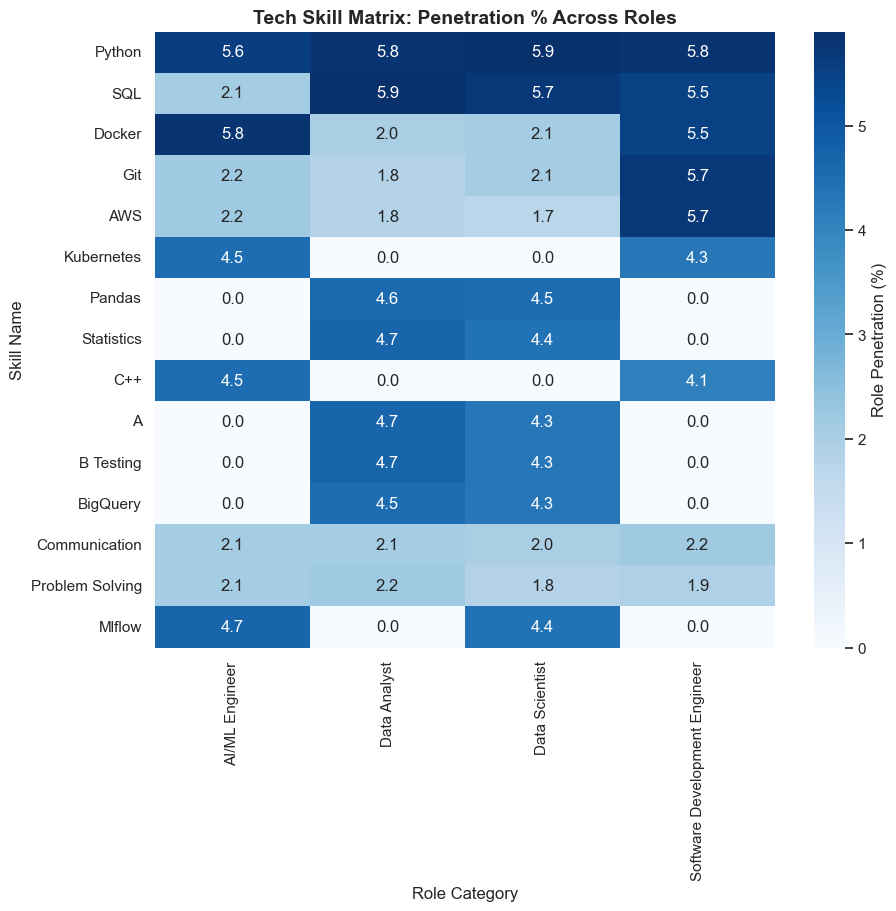

role_category,AI/ML Engineer,Data Analyst,Data Scientist,Software Development Engineer
skill_name,,,,
Python,5.6,5.8,5.9,5.8
SQL,2.1,5.9,5.7,5.5
Docker,5.8,2.0,2.1,5.5
Git,2.2,1.8,2.1,5.7
AWS,2.2,1.8,1.7,5.7
Kubernetes,4.5,0.0,0.0,4.3
Pandas,0.0,4.6,4.5,0.0
Statistics,0.0,4.7,4.4,0.0
C++,4.5,0.0,0.0,4.1


In [3]:
# Build Skill Demand Matrix across the 4 Roles
base_dir = "data/processed" if os.path.exists("data/processed") else "../data/processed"
fjs = pd.read_csv(os.path.join(base_dir, "fact_job_skills.csv"))
dim_skills = pd.read_csv(os.path.join(base_dir, "dim_skills.csv"))
dim_roles = pd.read_csv(os.path.join(base_dir, "dim_roles.csv"))
fact_jobs = pd.read_csv(os.path.join(base_dir, "fact_jobs.csv"))

# Merge
merged_skills = fjs.merge(dim_skills, on="skill_id").merge(fact_jobs[["job_id", "role_id"]], on="job_id").merge(dim_roles, on="role_id")

# Create Cross-tab of Skill vs Role %
skill_role_crosstab = pd.crosstab(
    merged_skills["skill_name"], 
    merged_skills["role_category"], 
    normalize="columns"
) * 100

# Select top 15 most prominent skills
top_overall_skills = merged_skills["skill_name"].value_counts().head(15).index
skill_matrix_top = skill_role_crosstab.loc[top_overall_skills].round(1)

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(skill_matrix_top, annot=True, fmt=".1f", cmap="Blues", cbar_kws={'label': 'Role Penetration (%)'})
plt.title("Tech Skill Matrix: Penetration % Across Roles", fontsize=14, fontweight="bold")
plt.xlabel("Role Category")
plt.ylabel("Skill Name")
plt.show()

skill_matrix_top


### 3. Skill Co-Occurrence Network

In [4]:
# Compute Co-occurrence for Data Analyst & AI/ML Skills
from itertools import combinations

co_occur_counter = Counter()
for skills_str in df["skills"]:
    skills_list = [s.strip() for s in skills_str.split(";")]
    for s1, s2 in combinations(sorted(skills_list), 2):
        co_occur_counter[(s1, s2)] += 1

# Top 10 most common skill pairs
top_pairs = co_occur_counter.most_common(10)
df_pairs = pd.DataFrame([{"Skill 1": p[0][0], "Skill 2": p[0][1], "Co-occurrences": p[1]} for p in top_pairs])
df_pairs


Out[4]: 
  Skill 1    Skill 2  Co-occurrences
0       A  B Testing            1019
1  Python        SQL             865
2      Cd         Ci             699
3  Docker     Python             650
4     AWS     Python             542
5  Docker        SQL             529
6     Git     Python             522
7     Git        SQL             486
8     AWS        SQL             464
9  Pandas     Python             428


,Skill 1,Skill 2,Co-occurrences
0,A,B Testing,1019
1,Python,SQL,865
2,Cd,Ci,699
3,Docker,Python,650
4,AWS,Python,542
5,Docker,SQL,529
6,Git,Python,522
7,Git,SQL,486
8,AWS,SQL,464
9,Pandas,Python,428
